In [17]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

In [ ]:
# colab -> Colab CPU -> Open terminal -> mkdir data -> cd data
# github 의 raw data 주소 확인
# wget https://github.com/code-archive-git/ai/raw/refs/heads/main/machine_learning/data/make_wave.npz

In [18]:
# 1. 데이터 불러오기
arr = np.load('/content/data/make_wave.npz')
x = arr['x']
y = arr['y']
print(x)
print(y)

[[-0.75275929]
 [ 2.70428584]
 [ 1.39196365]
 [ 0.59195091]
 [-2.06388816]
 [-2.06403288]
 [-2.65149833]
 [ 2.19705687]
 [ 0.60669007]
 [ 1.24843547]
 [-2.87649303]
 [ 2.81945911]
 [ 1.99465584]
 [-1.72596534]
 [-1.9090502 ]
 [-1.89957294]
 [-1.17454654]
 [ 0.14853859]
 [-0.40832989]
 [-1.25262516]
 [ 0.67111737]
 [-2.16303684]
 [-1.24713211]
 [-0.80182894]
 [-0.26358009]
 [ 1.71105577]
 [-1.80195731]
 [ 0.08540663]
 [ 0.55448741]
 [-2.72129752]
 [ 0.64526911]
 [-1.97685526]
 [-2.60969044]
 [ 2.69331322]
 [ 2.7937922 ]
 [ 1.85038409]
 [-1.17231738]
 [-2.41396732]
 [ 1.10539816]
 [-0.35908504]]
[-0.44822073  0.33122576  0.77932073  0.03497884 -1.38773632 -2.47196233
 -1.52730805  1.49417157  1.00032374  0.22956153 -1.05979555  0.7789638
  0.75418806 -1.51369739 -1.67303415 -0.90496988  0.08448544 -0.52734666
 -0.54114599 -0.3409073   0.21778193 -1.12469096  0.37299129  0.09756349
 -0.98618122  0.96695428 -1.13455014  0.69798591  0.43655826 -0.95652133
  0.03527881 -2.08581717 -0.4741103

In [19]:
# 2. 훈련데이터와 시험이터 분리
x_train,x_test,y_train,y_test = train_test_split(x,y,random_state=33)

# 3. 알고리즘 불러와서 학습 시키기
model = LinearRegression().fit(x_train,y_train)
print(f'train score : {model.score(x_train,y_train):.2f}')
print(f'test score : {model.score(x_test,y_test):.2f}')

train score : 0.72
test score : 0.60


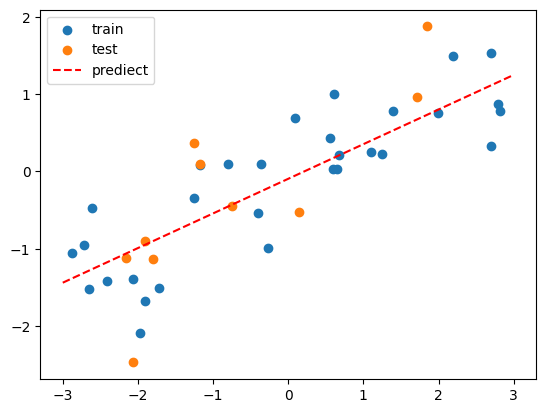

In [20]:
# 4. 학습데이터, 훈련데이터 확인
plt.scatter(x_train,y_train,label='train')
plt.scatter(x_test, y_test,label='test')

line = np.linspace(-3,3,1000).reshape(-1,1)
results = model.predict(line)
plt.plot(line,results,'r--', label='prediect')

plt.legend()
plt.show()

In [21]:
# 위와같은 선긋기가 나오게 된 이유(우리가 넣는것은 아니고 자동으로 계산 되어짐)
# coef_ : 각 속성의 가중치(입력 속성이 1개 이므로 한개만 나타난다.)
print(f'lr.coef_:{model.coef_}') # 입력된 속성의 가중치 값
print(f'lr.intercept_:{model.intercept_}') # 절편 파라메터

lr.coef_:[0.44819265]
lr.intercept_:-0.09475571208932401


파라메터가 많은 경우 라인이 어떻게 변하는지 확인

In [22]:
# 1. 데이터 불러오기
# wget https://github.com/code-archive-git/ai/raw/refs/heads/main/machine_learning/data/boston.npz
arr = np.load('/content/data/boston.npz')
print(list(arr.keys()))

['x', 'y']


In [23]:
# 2. 데이터 확인
x = arr['x']
y = arr['y']
print(x.shape) # 506개 층, 104개의 호 -> 입력 파라메터가 104인 데이터가 506개 있음
print(y.shape) # 그래서 입력에 대한 답은 506개 이다.

(506, 104)
(506,)


In [24]:
# 3. 테이터 분리
x_train,x_test,y_train,y_test = train_test_split(x,y,random_state=33)

# 4. 모델 선택 및 학습
model = LinearRegression().fit(x_train,y_train)

# 5. 결과 확인
print(f'train score: {model.score(x_train,y_train)}')
print(f'test score: {model.score(x_test,y_test)}')


train score: 0.941368878146875
test score: 0.847432548195407


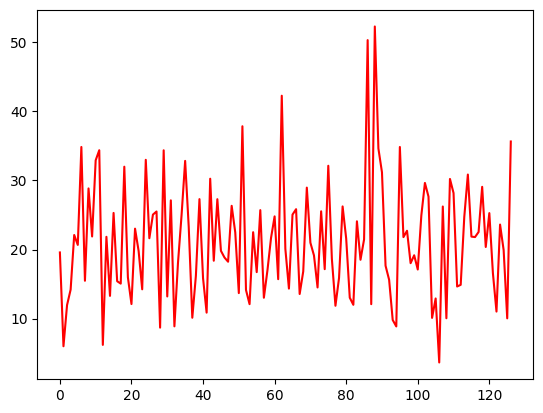

In [25]:
# y 값만 넣으면 x 는 자동으로 증가하게 된다.(pyplot 초반에 나온 내용)
plt.plot(model.predict(x_test),'r-')
plt.show()

In [26]:
# 파라메터 가중치(입력 속성이 104개 이므로 104개 씩 나타난다.)
print(f'lr.coef_:{model.coef_}') # [-3.83,1.348,-8.109,,1.199,...]
# 절편 파라메터 값
print(f'lr.intercept_:{model.intercept_}')

lr.coef_:[-3.83817101e+02  1.34801381e+01 -8.10948016e+01  1.19962924e+01
  5.46725621e+00  4.66148124e+01  4.09479515e+01 -5.98524024e+01
  3.90724893e+01 -2.91349155e-01  6.38182225e+00  1.65757399e+01
  1.40331802e+01  1.01775256e+01  7.33807693e+02  1.15021379e+03
  1.88840037e+02 -6.04622831e+00  5.14734520e+01 -3.73031920e+01
 -1.38435120e+02  5.51979364e+02 -1.32710152e+03  3.41129469e+02
 -7.32925455e+00  5.29217746e+01 -7.18008126e+00 -9.08838456e+00
 -9.76678309e-01 -4.71045405e+01  6.71287307e+00 -2.66767536e+00
  6.76930486e-01 -8.90400846e+00  2.57932658e+01 -8.86371091e+00
 -5.06977025e-01 -2.60184559e+01  2.48241023e+01 -1.42653134e+00
  4.17710672e+01  4.18772209e+01  5.72805435e+00  7.07064159e+01
  9.27220287e+00 -4.35487274e+00  3.50298538e+00  1.19091973e+01
 -1.04286122e+01  1.19962924e+01 -1.88061440e+01 -2.43255601e+01
  1.19817995e+00 -5.67209483e+00 -3.15366562e+00  6.33301875e+00
 -5.22878886e+00  5.50540951e-01 -9.02684074e+00 -2.39102497e+01
  2.33136710e+01

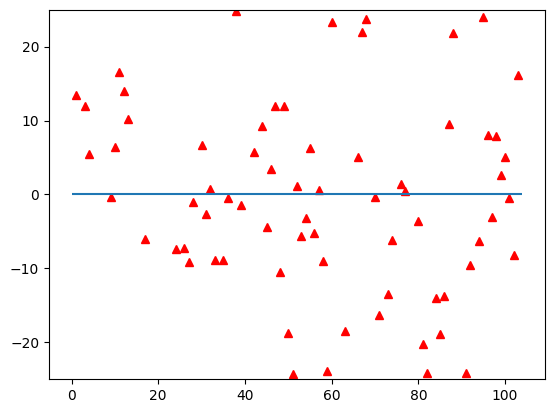

In [27]:
# 가중치를 눈으로 보자
plt.plot(model.coef_,'r^')
plt.ylim(-25,25)
plt.hlines(0,0,len(model.coef_)) # y지점, x시작점, x끝점
plt.show()